
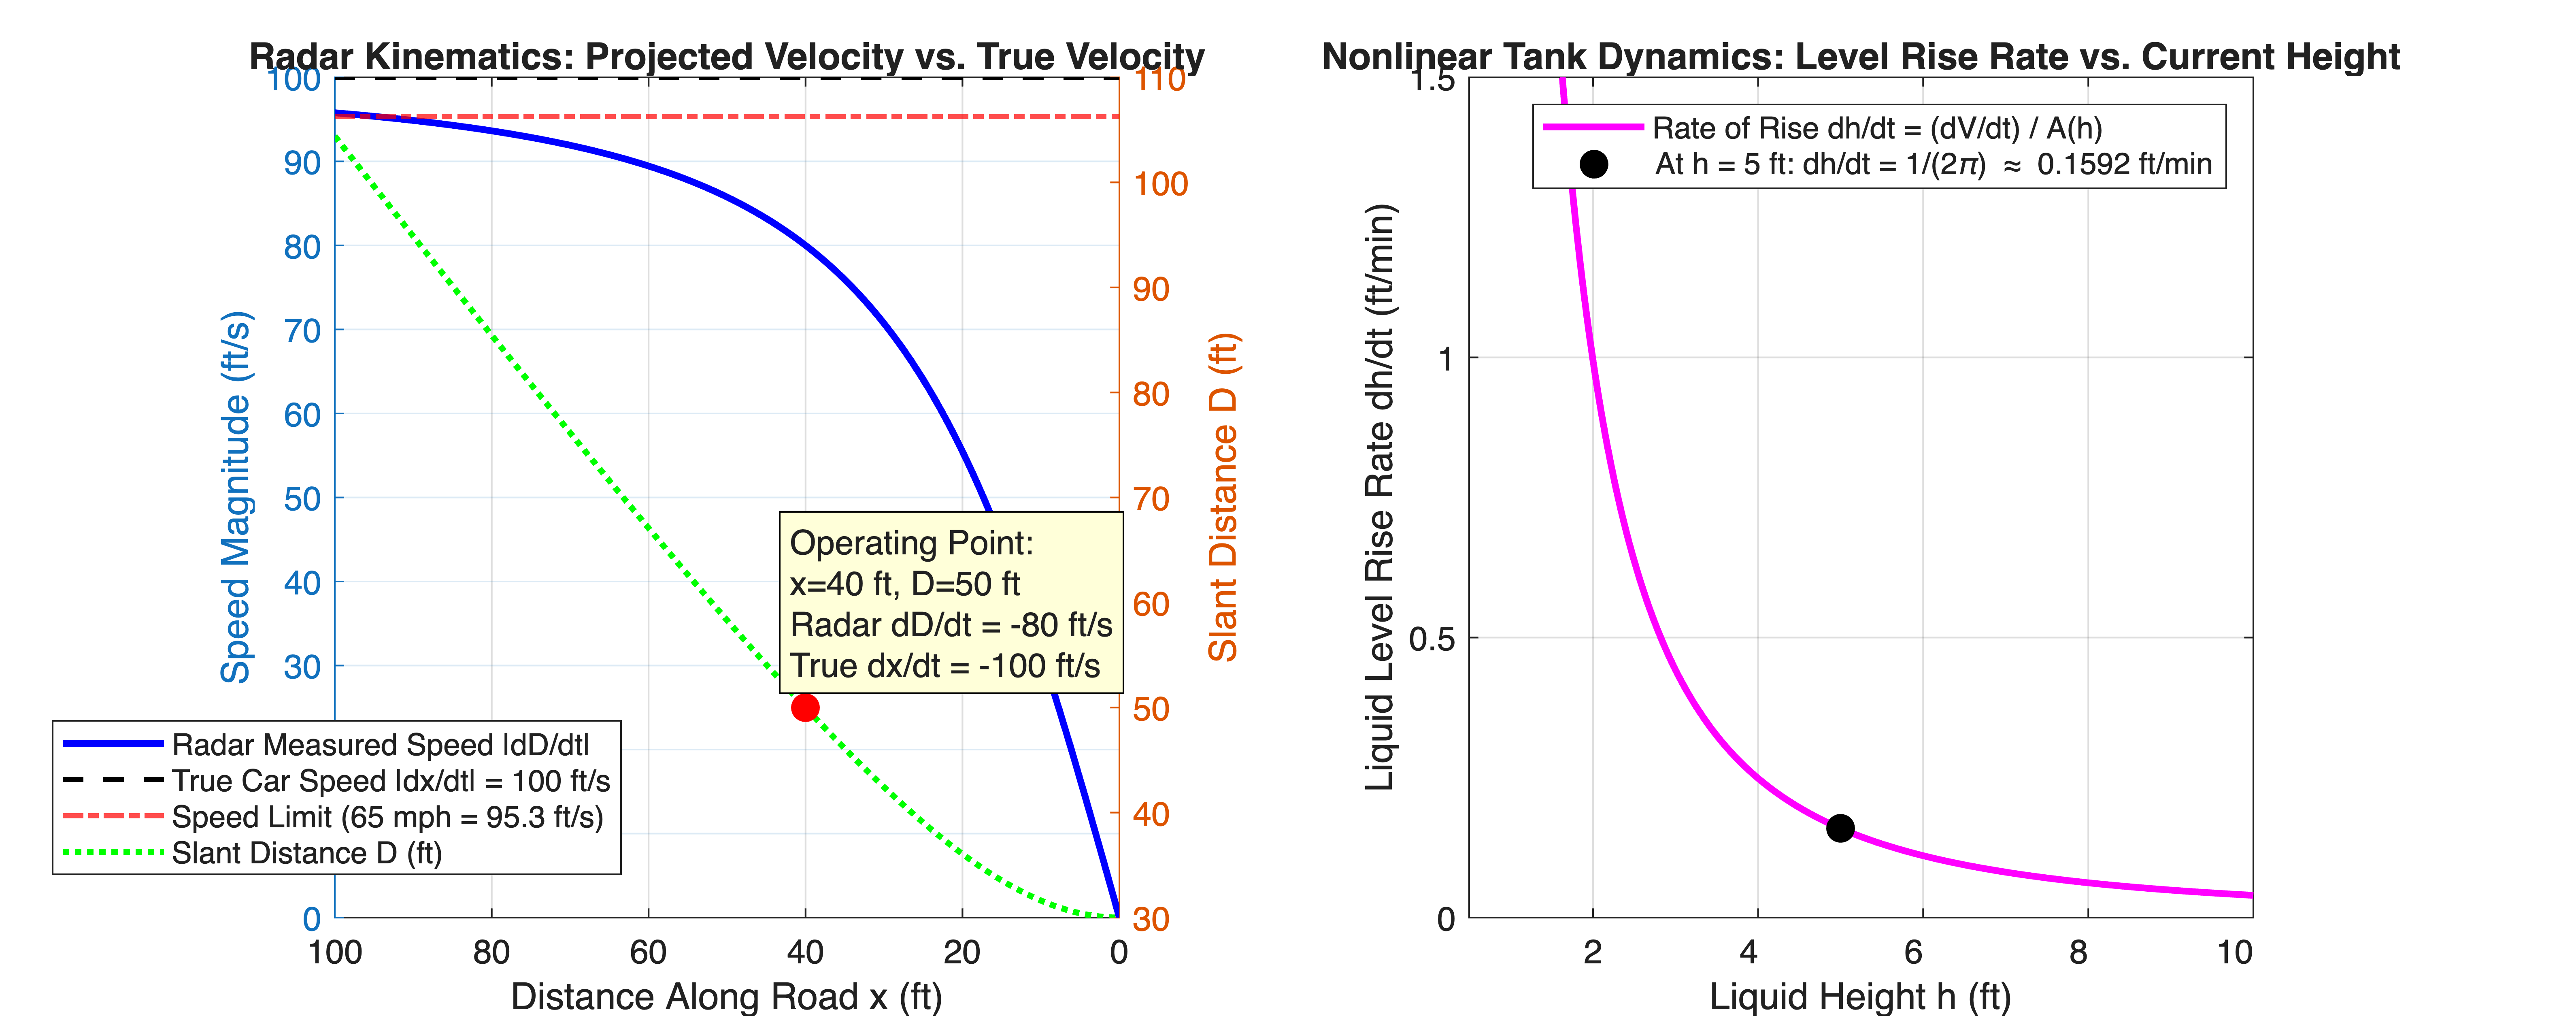

In [1]:
%% MIT 18.01 Lecture 12: Related Rates and Dynamic Kinematics Simulation
% Mathematical Tool Application: Used for state rate projection onto measurement spaces
% (Doppler radar observation Jacobians) and continuous mass-balance plant state modeling.


clear; clc; close all;


%% Part 1: Police Radar Speed Tracking Kinematics (Example 1)
% Geometric parameters: perpendicular road offset y_offset = 30 ft
y_offset = 30.0;
speed_limit_fps = 65.0 * 5280.0 / 3600.0; % 65 mph = 95.33 ft/s


% Car actual velocity along the road (approaching from positive x): vx = -100 ft/s
v_car_true = -100.0;


% Position coordinate along the road: x from 100 ft down to 0 ft
x_pos = linspace(100.0, 0.0, 400);


% Line-of-sight distance D(x) = sqrt(x^2 + y_offset^2)
D_slant = sqrt(x_pos.^2 + y_offset^2);


% Line-of-sight range rate: dD/dt = (x / D) * (dx/dt)
cos_theta = x_pos ./ D_slant;
dD_dt = cos_theta * v_car_true;


% Reconstructed car speed from radar measurement: dx/dt = (D / x) * (dD/dt)
v_reconstructed = (D_slant ./ x_pos) .* dD_dt;


figure('Color', 'w', 'Position', [100, 100, 1200, 480]);


subplot(1, 2, 1);
yyaxis left;
plot(x_pos, abs(dD_dt), 'b-', 'LineWidth', 2.0, 'DisplayName', 'Radar Measured Speed |dD/dt|'); hold on;
plot(x_pos, abs(v_car_true)*ones(size(x_pos)), 'k--', 'LineWidth', 1.5, 'DisplayName', 'True Car Speed |dx/dt| = 100 ft/s');
yline(speed_limit_fps, 'r-.', 'LineWidth', 1.5, 'DisplayName', 'Speed Limit (65 mph = 95.3 ft/s)');
ylabel('Speed Magnitude (ft/s)');
xlabel('Distance Along Road x (ft)');
set(gca, 'XDir', 'reverse'); % Approaching road direction


yyaxis right;
plot(x_pos, D_slant, 'g:', 'LineWidth', 1.8, 'DisplayName', 'Slant Distance D (ft)');
ylabel('Slant Distance D (ft)');


% Operating evaluation point: x = 40 ft, D = 50 ft
plot(40, 50, 'ro', 'MarkerSize', 8, 'MarkerFaceColor', 'r', 'HandleVisibility', 'off');
text(42, 60, sprintf('Operating Point:\nx=40 ft, D=50 ft\nRadar dD/dt = -80 ft/s\nTrue dx/dt = -100 ft/s'), ...
    'BackgroundColor', [1 1 0.85], 'EdgeColor', 'k');


grid on;
title('Radar Kinematics: Projected Velocity vs. True Velocity');
legend('Location', 'northwest');


%% Part 2: Inverted Conical Tank Drainage/Filling Dynamics (Example 2)
% Tank geometry: top radius R0 = 4 ft, total height H0 = 10 ft
% Inflow volume rate: dV/dt = 2 ft^3/min
R0 = 4.0;
H0 = 10.0;
dV_dt = 2.0;


% Water height range from 0.5 ft to 10 ft
h_span = linspace(0.5, 10.0, 300);


% Conical cross-section area: A(h) = pi * ( (R0/H0)*h )^2
A_cross = pi * ((R0 / H0) * h_span).^2;


% Rate of liquid level rise: dh/dt = (dV/dt) / A(h)
dh_dt = dV_dt ./ A_cross;


% Evaluated state: h = 5 ft
h_eval = 5.0;
dh_dt_eval = dV_dt / (pi * ((R0 / H0) * h_eval)^2); % 1 / (2*pi) approx 0.1592 ft/min


subplot(1, 2, 2);
plot(h_span, dh_dt, 'm-', 'LineWidth', 2.0, 'DisplayName', 'Rate of Rise dh/dt = (dV/dt) / A(h)'); hold on;
plot(h_eval, dh_dt_eval, 'ko', 'MarkerSize', 8, 'MarkerFaceColor', 'k', ...
    'DisplayName', sprintf('At h = 5 ft: dh/dt = 1/(2\\pi) \\approx %.4f ft/min', dh_dt_eval));


grid on;
xlim([0.5, 10]); ylim([0, 1.5]);
xlabel('Liquid Height h (ft)');
ylabel('Liquid Level Rise Rate dh/dt (ft/min)');
title('Nonlinear Tank Dynamics: Level Rise Rate vs. Current Height');
legend('Location', 'northeast');